# TrafficEye LLM Model Comparison

Direct evaluation of LLM models for MMR-to-description matching using Chat Completions API with tool calling.

**Goal**: Find the best model (accuracy vs cost) and refine the prompt.

## 1. Setup & Data Loading

In [ ]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
from openai import OpenAI
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List, Tuple
from collections import Counter
import time

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
# Load API key from Secrets.xcconfig
def load_api_key():
    xcconfig_path = Path("../thing-finder/Secrets.xcconfig")
    if xcconfig_path.exists():
        with open(xcconfig_path) as f:
            for line in f:
                if line.startswith("OPENAI_API"):
                    parts = line.split("=", 1)
                    if len(parts) == 2:
                        return parts[1].strip()
    raise ValueError("API key not found in Secrets.xcconfig")

api_key = load_api_key()
client = OpenAI(api_key=api_key)
print("✓ OpenAI client initialized")

In [ ]:
# Load test cases
def load_test_cases():
    cases = []
    with open("data/test_cases.jsonl") as f:
        for line in f:
            cases.append(json.loads(line)["item"])
    return cases

test_cases = load_test_cases()
print(f"✓ Loaded {len(test_cases)} test cases")

# Show distribution
decisions = Counter(c["expected_decision"] for c in test_cases)
print(f"\nDistribution: {dict(decisions)}")

## 2. Production Prompt (from TrafficEyeVerifier.swift)

In [ ]:
SYSTEM_PROMPT = """You are a vehicle verification assistant. Your task is to determine if a machine learning model's prediction about a vehicle (make, model, color) matches what the user described.

You will receive:
1. MMR (Make-Model-Recognition) API output with confidence scores
2. User's natural language description of their vehicle

Your job:
- Compare the API prediction with the user's description
- Account for:
  * Color variations (silver/gray, white/cream are similar)
  * Abbreviations (Chevy = Chevrolet, VW = Volkswagen)
  * Model trims (Civic LX vs Civic)
  * Partial user info (user says "Honda" but API says "Red Honda Civic" is still a match)
- Consider confidence scores in MMR output

Decision guidelines:
- **match**: Confident they refer to the same vehicle
- **mismatch**: Confident they are different vehicles (wrong make, model, or color)
- **maybe**: Uncertain due to low confidence scores, ambiguous info, or missing details"""

def create_user_prompt(mmr_json: str, user_description: str) -> str:
    return f"""MMR API Output:
{mmr_json}

User Description: "{user_description}"

Does the API prediction match the user's vehicle?"""

TOOL_SCHEMA = {
    "type": "function",
    "function": {
        "name": "submit_match_decision",
        "description": "Submit the verification probability and justification.",
        "parameters": {
            "type": "object",
            "properties": {
                "probability_match": {
                    "type": "number",
                    "description": "Estimated probability (0-1) that the ML prediction refers to the same car as described by the user.",
                },
                "semantic_reason": {
                    "type": "string",
                    "description": "Match if confident they are the same car. Mismatch if confident they are different. Maybe when uncertain or info is missing.",
                    "enum": ["match", "maybe", "mismatch"],
                },
            },
            "required": ["probability_match", "semantic_reason"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

print("✓ Prompts loaded")

## 3. Evaluation Functions

In [ ]:
def compute_reject_reason(semantic_reason: str, info_quality: str) -> str:
    """Map semantic_reason + info_quality to RejectReason (matching TrafficEyeVerifier logic)."""
    if info_quality == "high":
        if semantic_reason == "match":
            return "success"
        elif semantic_reason == "maybe":
            return "low_confidence"
        else:  # mismatch
            return "wrong_model_or_color"
    else:  # medium or low quality
        if semantic_reason == "match":
            return "success"
        else:
            return "insufficient_info"


def run_single_case(mmr_json: str, user_description: str, model: str = "gpt-4.1-mini") -> Dict:
    """Run a single test case through the LLM."""
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": create_user_prompt(mmr_json, user_description)},
            ],
            tools=[TOOL_SCHEMA],
            tool_choice="required",
            temperature=0,
        )
        
        # Parse tool call
        tool_call = response.choices[0].message.tool_calls[0]
        args = json.loads(tool_call.function.arguments)
        
        return {
            "semantic_reason": args["semantic_reason"],
            "probability_match": args["probability_match"],
            "tokens_used": response.usage.total_tokens,
            "error": None,
        }
    except Exception as e:
        return {
            "semantic_reason": None,
            "probability_match": None,
            "tokens_used": 0,
            "error": str(e),
        }


def grade_result(test_case: Dict, result: Dict) -> Dict:
    """Grade a single result against expected values."""
    if result["error"]:
        return {
            "correct_decision": False,
            "correct_reject_reason": False,
            "probability_error": None,
        }
    
    # Check semantic_reason
    correct_decision = result["semantic_reason"] == test_case["expected_decision"]
    
    # Compute actual reject_reason from result + info_quality
    actual_reject_reason = compute_reject_reason(
        result["semantic_reason"], test_case["info_quality"]
    )
    correct_reject_reason = actual_reject_reason == test_case["expected_reject_reason"]
    
    # Probability error
    prob_error = abs(result["probability_match"] - test_case["expected_probability"])
    
    return {
        "correct_decision": correct_decision,
        "correct_reject_reason": correct_reject_reason,
        "probability_error": prob_error,
        "actual_reject_reason": actual_reject_reason,
    }

print("✓ Evaluation functions defined")

## 4. Run Evaluation

In [ ]:
def run_evaluation(test_cases: List[Dict], model: str = "gpt-4.1-mini", limit: int = None) -> pd.DataFrame:
    """Run evaluation on all test cases."""
    results = []
    cases_to_run = test_cases[:limit] if limit else test_cases
    
    print(f"Running {len(cases_to_run)} test cases with {model}...")
    
    for i, test_case in enumerate(cases_to_run, 1):
        if i % 10 == 0:
            print(f"  Progress: {i}/{len(cases_to_run)}")
        
        # Run LLM
        result = run_single_case(
            test_case["mmr_json"],
            test_case["user_description"],
            model=model,
        )
        
        # Grade
        grading = grade_result(test_case, result)
        
        # Combine
        results.append({
            "test_case_type": test_case["test_case_type"],
            "info_quality": test_case["info_quality"],
            "info_score": test_case["info_score"],
            "user_description": test_case["user_description"],
            "mmr_json": test_case["mmr_json"],
            "expected_decision": test_case["expected_decision"],
            "expected_probability": test_case["expected_probability"],
            "expected_reject_reason": test_case["expected_reject_reason"],
            "actual_decision": result["semantic_reason"],
            "actual_probability": result["probability_match"],
            "actual_reject_reason": grading.get("actual_reject_reason"),
            "correct_decision": grading["correct_decision"],
            "correct_reject_reason": grading["correct_reject_reason"],
            "probability_error": grading["probability_error"],
            "tokens_used": result["tokens_used"],
            "error": result["error"],
        })
        
        # Rate limit
        time.sleep(0.1)
    
    df = pd.DataFrame(results)
    print(f"\n✓ Completed {len(df)} cases")
    return df

In [ ]:
# Run evaluation (start with small sample)
results_df = run_evaluation(test_cases, model="gpt-4.1-mini", limit=20)
results_df.head(10)

## 5. Metrics & Analysis

In [ ]:
def compute_metrics(df: pd.DataFrame) -> Dict:
    """Compute evaluation metrics."""
    # Filter out errors
    valid_df = df[df["error"].isna()]
    
    metrics = {
        "total_cases": len(df),
        "errors": len(df) - len(valid_df),
        "decision_accuracy": valid_df["correct_decision"].mean(),
        "reject_reason_accuracy": valid_df["correct_reject_reason"].mean(),
        "probability_mae": valid_df["probability_error"].mean(),
        "total_tokens": valid_df["tokens_used"].sum(),
    }
    
    return metrics


def print_metrics(metrics: Dict, model: str):
    """Pretty print metrics."""
    print(f"\n{'='*60}")
    print(f"METRICS: {model}")
    print(f"{'='*60}")
    print(f"Total cases:              {metrics['total_cases']}")
    print(f"Errors:                   {metrics['errors']}")
    print(f"Decision accuracy:        {metrics['decision_accuracy']:.1%}")
    print(f"Reject reason accuracy:   {metrics['reject_reason_accuracy']:.1%}")
    print(f"Probability MAE:          {metrics['probability_mae']:.3f}")
    print(f"Total tokens:             {metrics['total_tokens']:,}")
    print(f"{'='*60}")


metrics = compute_metrics(results_df)
print_metrics(metrics, "gpt-4.1-mini")

In [ ]:
# Breakdown by test type
def analyze_by_type(df: pd.DataFrame):
    valid_df = df[df["error"].isna()]
    
    by_type = valid_df.groupby("test_case_type").agg({
        "correct_decision": "mean",
        "correct_reject_reason": "mean",
        "probability_error": "mean",
        "test_case_type": "count",
    }).rename(columns={"test_case_type": "count"})
    
    by_type = by_type.sort_values("correct_decision", ascending=False)
    return by_type

by_type = analyze_by_type(results_df)
print("\nAccuracy by Test Type:")
print(by_type)

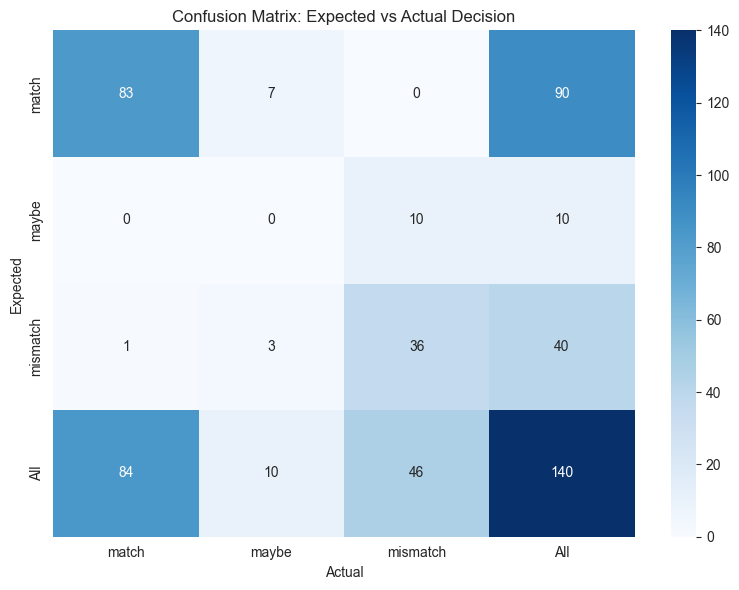

In [37]:
# Confusion matrix
def plot_confusion_matrix(df: pd.DataFrame):
    valid_df = df[df["error"].isna()]
    
    confusion = pd.crosstab(
        valid_df["expected_decision"],
        valid_df["actual_decision"],
        margins=True,
    )
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues")
    plt.title("Confusion Matrix: Expected vs Actual Decision")
    plt.ylabel("Expected")
    plt.xlabel("Actual")
    plt.tight_layout()
    plt.show()
nano_df = pd.read_csv("results/gpt-5.4-nano_results.csv")
plot_confusion_matrix(nano_df)

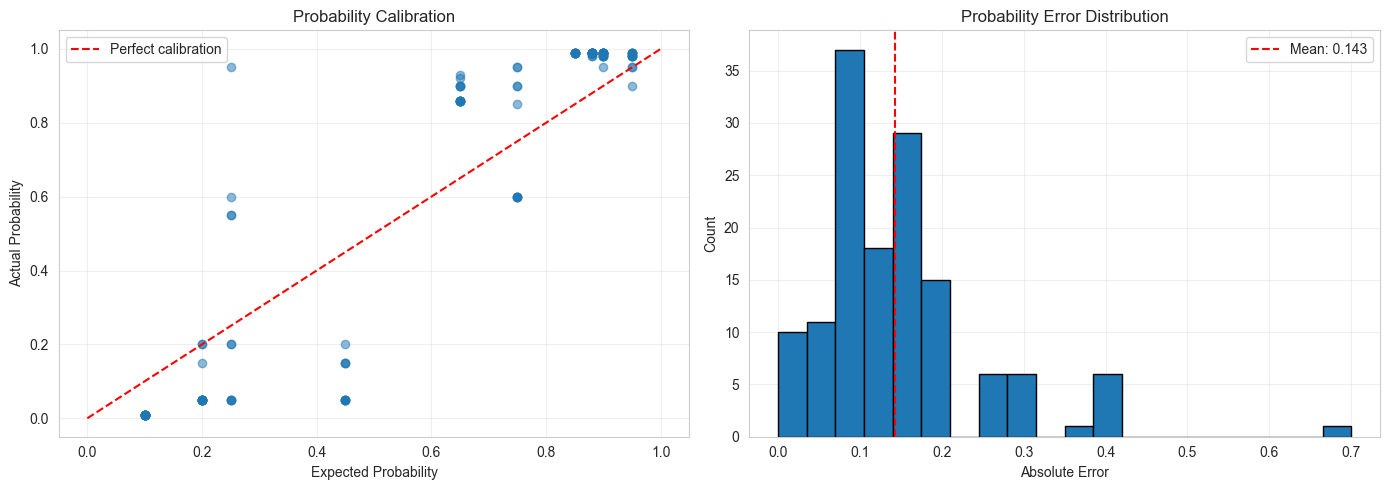

In [38]:
# Probability calibration
def plot_probability_calibration(df: pd.DataFrame):
    valid_df = df[df["error"].isna()]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Scatter plot
    ax1.scatter(
        valid_df["expected_probability"],
        valid_df["actual_probability"],
        alpha=0.5,
    )
    ax1.plot([0, 1], [0, 1], "r--", label="Perfect calibration")
    ax1.set_xlabel("Expected Probability")
    ax1.set_ylabel("Actual Probability")
    ax1.set_title("Probability Calibration")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Error distribution
    ax2.hist(valid_df["probability_error"], bins=20, edgecolor="black")
    ax2.set_xlabel("Absolute Error")
    ax2.set_ylabel("Count")
    ax2.set_title("Probability Error Distribution")
    ax2.axvline(valid_df["probability_error"].mean(), color="r", linestyle="--", label=f"Mean: {valid_df['probability_error'].mean():.3f}")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_probability_calibration(nano_df)

## 6. Failure Analysis

In [42]:
# Show worst failures
def show_failures(df: pd.DataFrame, n: int = 10):
    failures = df[~df["correct_decision"] & df["error"].isna()].copy()
    failures = failures.sort_values("probability_error", ascending=False)
    
    print(f"\nTop {n} Failures:\n")
    for i, row in failures.head(n).iterrows():
        mmr = json.loads(row["mmr_json"])
        print(f"{i+1}. {row['test_case_type']} (quality={row['info_quality']})")
        print(f"   API: {mmr['color']['value']} {mmr['make']['value']} {mmr['model']['value']}")
        print(f"   User: {row['user_description']}")
        print(f"   Expected: {row['expected_decision']} (prob={row['expected_probability']})")
        print(f"   Actual: {row['actual_decision']} (prob={row['actual_probability']:.2f})")
        print(f"   Reject reason: expected={row['expected_reject_reason']}, actual={row['actual_reject_reason']}")
        print()

show_failures(nano_df, n=20)


Top 20 Failures:

116. wrong_color (quality=high)
   API: WHITE Lexus RX
   User: gray Lexus RX
   Expected: mismatch (prob=0.25)
   Actual: match (prob=0.95)
   Reject reason: expected=wrong_model_or_color, actual=success

136. model_similarity (quality=high)
   API: RED BMW 3 Series
   User: red BMW 5 Series
   Expected: maybe (prob=0.45)
   Actual: mismatch (prob=0.05)
   Reject reason: expected=low_confidence, actual=wrong_model_or_color

54. model_similarity (quality=medium)
   API: PURPLE Chevrolet Malibu
   User: purple Chevrolet Impala
   Expected: maybe (prob=0.45)
   Actual: mismatch (prob=0.05)
   Reject reason: expected=insufficient_info, actual=insufficient_info

68. model_similarity (quality=medium)
   API: WHITE Toyota Camry
   User: white Toyota Corolla
   Expected: maybe (prob=0.45)
   Actual: mismatch (prob=0.05)
   Reject reason: expected=insufficient_info, actual=insufficient_info

71. model_similarity (quality=medium)
   API: RED Toyota Camry
   User: red Toyota C

## 7. Run Full Evaluation (All 140 Cases)

Uncomment and run when ready:

In [ ]:
# # Full evaluation
# full_results = run_evaluation(test_cases, model="gpt-4.1-mini", limit=None)
# full_metrics = compute_metrics(full_results)
# print_metrics(full_metrics, "gpt-4.1-mini")

# # Save results
# full_results.to_csv("results/gpt-4.1-mini_results.csv", index=False)
# print("\n✓ Results saved to results/gpt-4.1-mini_results.csv")

## 8. Model Comparison

Run multiple models and compare:

In [ ]:
# # Models to compare
# MODELS = [
#     "gpt-4.1-mini",
#     "gpt-4.1",
#     "gpt-5.4-nano",
#     "gpt-5.4-mini",
# ]

# comparison_results = {}
# for model in MODELS:
#     print(f"\n{'='*60}")
#     print(f"Running {model}...")
#     print(f"{'='*60}")
#     
#     results = run_evaluation(test_cases, model=model, limit=None)
#     metrics = compute_metrics(results)
#     
#     comparison_results[model] = {
#         "results": results,
#         "metrics": metrics,
#     }
#     
#     print_metrics(metrics, model)
#     
#     # Save individual results
#     results.to_csv(f"results/{model}_results.csv", index=False)

# # Create comparison table
# comparison_df = pd.DataFrame({
#     model: data["metrics"]
#     for model, data in comparison_results.items()
# }).T

# print("\n" + "="*60)
# print("MODEL COMPARISON")
# print("="*60)
# print(comparison_df)

# # Save comparison
# comparison_df.to_csv("results/model_comparison.csv")
# print("\n✓ Comparison saved to results/model_comparison.csv")